In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Load the original dataset
df = pd.read_csv("../data/raw/Maternal_Health_Risk.csv")

# Create a folder for charts
os.makedirs("../docs/figures", exist_ok=True)

# Display the first records
display(df.head())

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()


,Patient ID,Name,Age,Body Temperature(F),Heart rate(bpm),Systolic Blood Pressure(mm Hg),Diastolic Blood Pressure(mm Hg),BMI(kg/m 2),Blood Glucose(HbA1c),Blood Glucose(Fasting hour-mg/dl),Status
0,101,Bhavana,20,97.5,91,161,100,24.9,41,5.8,high risk
1,102,Mithila,45,97.7,99,99,94,22.1,36,5.7,high risk
2,103,Phoolan,29,98.6,84,129,87,19.0,42,6.4,mid risk
3,104,Joyonti,26,99.5,135,161,101,23.7,46,4.5,high risk
4,105,Vana,38,102.5,51,106,91,18.8,38,4.3,high risk


Dataset shape: (6103, 11)

Column names:
['Patient ID', 'Name', 'Age', 'Body Temperature(F) ', 'Heart rate(bpm)', 'Systolic Blood Pressure(mm Hg)', 'Diastolic Blood Pressure(mm Hg)', 'BMI(kg/m 2)', 'Blood Glucose(HbA1c)', 'Blood Glucose(Fasting hour-mg/dl)', 'Status']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6103 entries, 0 to 6102
Data columns (total 11 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Patient ID                         6103 non-null   int64  
 1   Name                               6103 non-null   object 
 2   Age                                6103 non-null   int64  
 3   Body Temperature(F)                6103 non-null   float64
 4   Heart rate(bpm)                    6103 non-null   int64  
 5   Systolic Blood Pressure(mm Hg)     6103 non-null   int64  
 6   Diastolic Blood Pressure(mm Hg)    6103 non-null   int64  
 7   BMI(kg/m 2)          

In [2]:

# Count missing values in each column
missing_values = df.isnull().sum()

print("MISSING VALUES:")
print(missing_values)

print("\nMissing value percentages:")
missing_percentage = (df.isnull().sum() / len(df)) * 100
print(missing_percentage.round(2))


MISSING VALUES:
Patient ID                           0
Name                                 0
Age                                  0
Body Temperature(F)                  0
Heart rate(bpm)                      0
Systolic Blood Pressure(mm Hg)       0
Diastolic Blood Pressure(mm Hg)      0
BMI(kg/m 2)                          0
Blood Glucose(HbA1c)                 0
Blood Glucose(Fasting hour-mg/dl)    0
Status                               0
dtype: int64

Missing value percentages:
Patient ID                           0.0
Name                                 0.0
Age                                  0.0
Body Temperature(F)                  0.0
Heart rate(bpm)                      0.0
Systolic Blood Pressure(mm Hg)       0.0
Diastolic Blood Pressure(mm Hg)      0.0
BMI(kg/m 2)                          0.0
Blood Glucose(HbA1c)                 0.0
Blood Glucose(Fasting hour-mg/dl)    0.0
Status                               0.0
dtype: float64


In [3]:

# Count duplicate rows
duplicates = df.duplicated().sum()

print("Number of duplicate records:", duplicates)

# Calculate percentage of duplicates
duplicate_percentage = (duplicates / len(df)) * 100

print("Duplicate percentage:", round(duplicate_percentage, 2), "%")


Number of duplicate records: 0
Duplicate percentage: 0.0 %


In [4]:

# Statistical summary of numerical columns
display(df.describe())

# Check data types
print("\nDATA TYPES:")
print(df.dtypes)

# Check unique values in categorical columns
print("\nCATEGORICAL VALUES:")

categorical_columns = df.select_dtypes(
    include=["object", "category"]
).columns

for column in categorical_columns:
    print("\n", column)
    print(df[column].value_counts(dropna=False))


,Patient ID,Age,Body Temperature(F),Heart rate(bpm),Systolic Blood Pressure(mm Hg),Diastolic Blood Pressure(mm Hg),BMI(kg/m 2),Blood Glucose(HbA1c),Blood Glucose(Fasting hour-mg/dl)
count,6103.000000,6103.000000,6103.000000,6103.000000,6103.000000,6103.000000,6103.000000,6103.000000,6103.000000
mean,3152.000000,26.425037,98.665574,86.100770,129.218253,87.257578,21.435581,37.904473,5.504752
std,1761.928678,6.390205,1.590983,22.627587,17.234217,7.793099,2.157060,4.400272,0.905327
min,101.000000,15.000000,39.600000,45.000000,90.000000,9.000000,14.900000,30.000000,3.500000
25%,1626.500000,22.000000,98.600000,72.000000,120.000000,82.000000,19.600000,34.000000,4.800000
50%,3152.000000,25.000000,98.600000,80.000000,128.000000,87.000000,21.300000,38.000000,5.700000
75%,4677.500000,30.000000,98.800000,91.000000,141.000000,92.000000,23.100000,41.000000,6.000000
max,6203.000000,250.000000,104.000000,150.000000,169.000000,142.000000,27.900000,50.000000,8.900000



DATA TYPES:
Patient ID                             int64
Name                                  object
Age                                    int64
Body Temperature(F)                  float64
Heart rate(bpm)                        int64
Systolic Blood Pressure(mm Hg)         int64
Diastolic Blood Pressure(mm Hg)        int64
BMI(kg/m 2)                          float64
Blood Glucose(HbA1c)                   int64
Blood Glucose(Fasting hour-mg/dl)    float64
Status                                object
dtype: object

CATEGORICAL VALUES:

 Name
Name
Nitya       3
Devi        3
Ratna       3
Hema        3
Bhagya      3
           ..
Arunima     1
Jayanthi    1
Jyothsna    1
Chayla      1
Aashrita    1
Name: count, Length: 5794, dtype: int64

 Status
Status
high risk    2059
mid risk     2043
low risk     2001
Name: count, dtype: int64


In [5]:

# Identify columns without assuming their exact spelling
def find_column(possible_names):
    for col in df.columns:
        normalized = col.lower().replace("_", "").replace(" ", "")
        if normalized in possible_names:
            return col
    return None

target_col = find_column(["risklevel"])
age_col = find_column(["age"])
systolic_col = find_column(["systolicbp"])
temperature_col = find_column(["bodytemp", "bodytemperature"])

print("Target column:", target_col)
print("Age column:", age_col)
print("Systolic BP column:", systolic_col)
print("Temperature column:", temperature_col)


Target column: None
Age column: Age
Systolic BP column: None
Temperature column: None


In [6]:

print("ACTUAL COLUMN NAMES:")

for col in df.columns:
    print(repr(col))


ACTUAL COLUMN NAMES:
'Patient ID'
'Name'
'Age'
'Body Temperature(F) '
'Heart rate(bpm)'
'Systolic Blood Pressure(mm Hg)'
'Diastolic Blood Pressure(mm Hg)'
'BMI(kg/m 2)'
'Blood Glucose(HbA1c)'
'Blood Glucose(Fasting hour-mg/dl)'
'Status'


In [7]:
print(df.columns.tolist())

['Patient ID', 'Name', 'Age', 'Body Temperature(F) ', 'Heart rate(bpm)', 'Systolic Blood Pressure(mm Hg)', 'Diastolic Blood Pressure(mm Hg)', 'BMI(kg/m 2)', 'Blood Glucose(HbA1c)', 'Blood Glucose(Fasting hour-mg/dl)', 'Status']


In [8]:

# Remove accidental spaces at the beginning or end of column names
df.columns = df.columns.str.strip()

# Identify the actual columns
target_col = "Status"
age_col = "Age"
systolic_col = "Systolic Blood Pressure(mm Hg)"
temperature_col = "Body Temperature(F)"

print("Target column:", target_col)
print("Age column:", age_col)
print("Systolic BP column:", systolic_col)
print("Temperature column:", temperature_col)

# Confirm that all required columns exist
required_columns = [
    target_col,
    age_col,
    systolic_col,
    temperature_col
]

for col in required_columns:
    print(col, ":", col in df.columns)


Target column: Status
Age column: Age
Systolic BP column: Systolic Blood Pressure(mm Hg)
Temperature column: Body Temperature(F)
Status : True
Age : True
Systolic Blood Pressure(mm Hg) : True
Body Temperature(F) : True


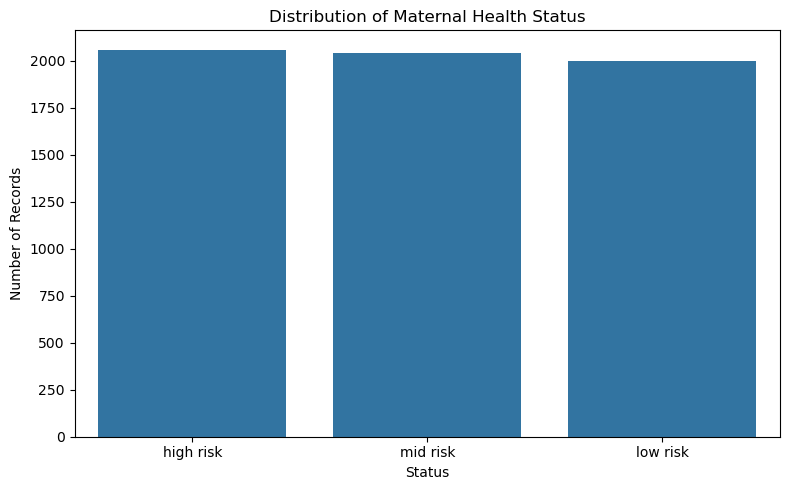

In [9]:

plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="Status")

plt.title("Distribution of Maternal Health Status")
plt.xlabel("Status")
plt.ylabel("Number of Records")
plt.tight_layout()

plt.savefig("../docs/figures/chart1_risk_distribution.png")
plt.show()


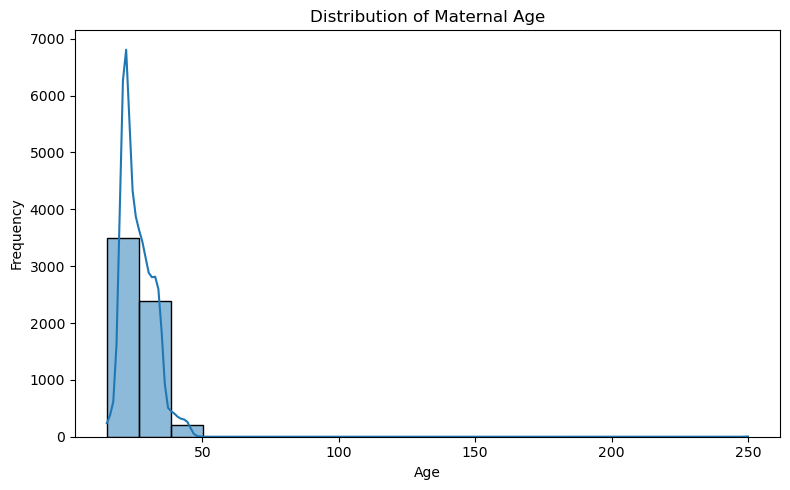

In [10]:

plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="Age", bins=20, kde=True)

plt.title("Distribution of Maternal Age")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.tight_layout()

plt.savefig("../docs/figures/chart2_age_distribution.png")
plt.show()


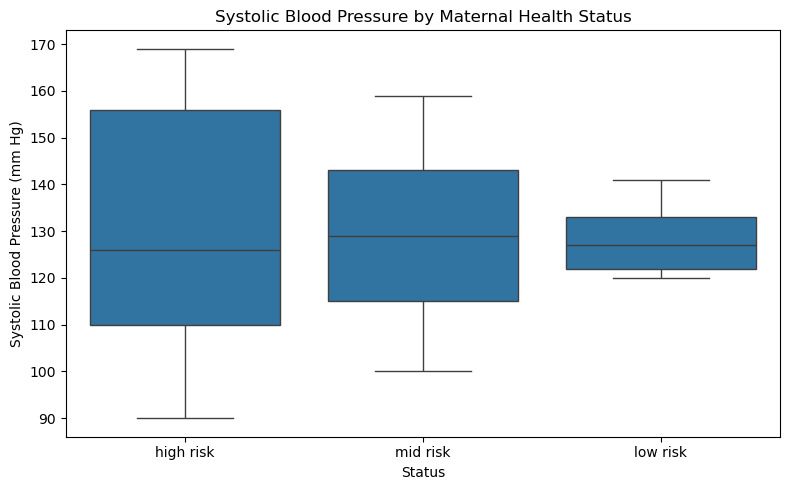

In [11]:

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Status",
    y="Systolic Blood Pressure(mm Hg)"
)

plt.title("Systolic Blood Pressure by Maternal Health Status")
plt.xlabel("Status")
plt.ylabel("Systolic Blood Pressure (mm Hg)")
plt.tight_layout()

plt.savefig("../docs/figures/chart3_blood_pressure.png")
plt.show()


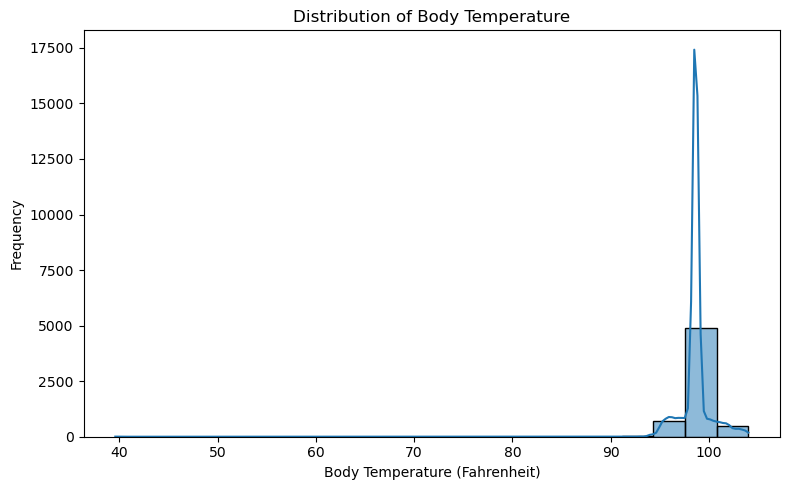

In [12]:

plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="Body Temperature(F)",
    bins=20,
    kde=True
)

plt.title("Distribution of Body Temperature")
plt.xlabel("Body Temperature (Fahrenheit)")
plt.ylabel("Frequency")
plt.tight_layout()

plt.savefig("../docs/figures/chart4_temperature.png")
plt.show()


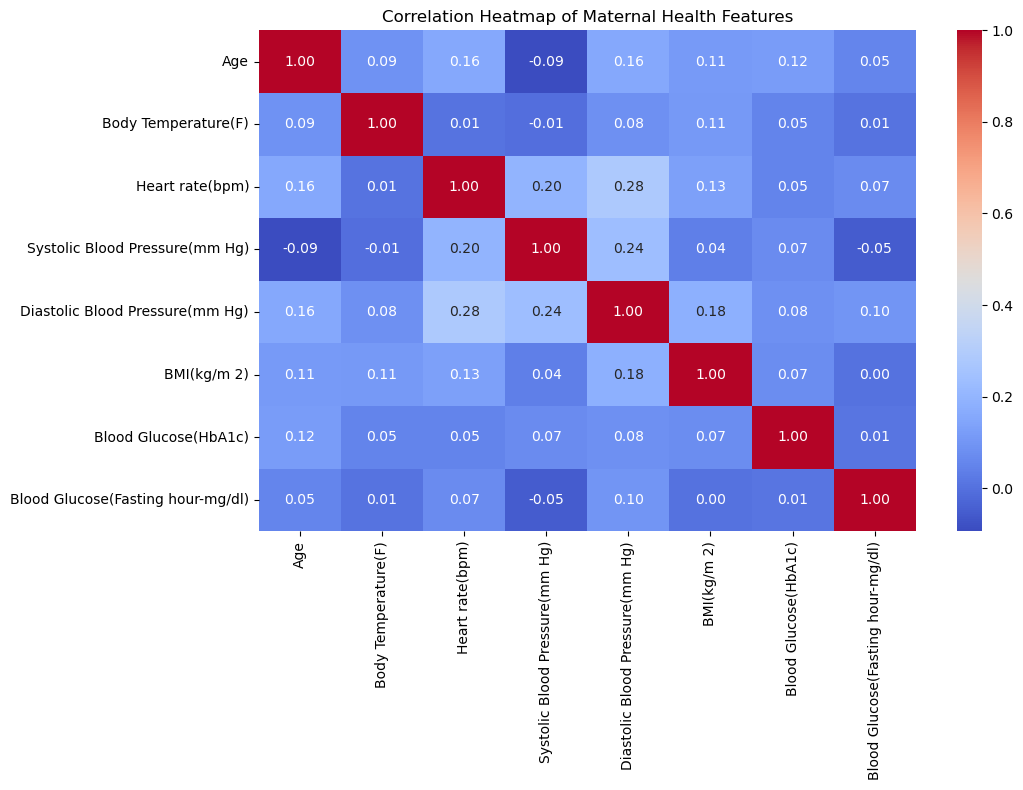

In [13]:

plt.figure(figsize=(11, 8))

# Exclude patient identifiers and names
numeric_df = df.drop(
    columns=["Patient ID", "Name"],
    errors="ignore"
).select_dtypes(include=np.number)

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Maternal Health Features")
plt.tight_layout()

plt.savefig("../docs/figures/chart5_correlation.png")
plt.show()


In [14]:
print("Status categories:")
print(df["Status"].value_counts(dropna=False))

Status categories:
Status
high risk    2059
mid risk     2043
low risk     2001
Name: count, dtype: int64


In [15]:
import pandas as pd

df = pd.read_csv("../data/raw/Maternal_Health_Risk.csv")

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 6103
Number of columns: 11


In [16]:
# 1. Check missing values
print("MISSING VALUES")
print(df.isnull().sum())

# 2. Check duplicate records
print("\nDUPLICATE RECORDS")
print(df.duplicated().sum())

# 3. Check data types
print("\nDATA TYPES")
print(df.dtypes)

# 4. Check potential outliers using the IQR method
print("\nPOTENTIAL OUTLIERS")

numeric_cols = df.select_dtypes(include="number").columns.drop(
    "Patient ID", errors="ignore"
)

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    outliers = ((df[col] < Q1 - 1.5 * IQR) |
                (df[col] > Q3 + 1.5 * IQR)).sum()

    print(col, ":", outliers)

# 5. Check inconsistent categorical values
print("\nCATEGORICAL VALUES")

for col in df.select_dtypes(include="object").columns:
    print(f"\n{col}:")
    print(df[col].value_counts(dropna=False))

MISSING VALUES
Patient ID                           0
Name                                 0
Age                                  0
Body Temperature(F)                  0
Heart rate(bpm)                      0
Systolic Blood Pressure(mm Hg)       0
Diastolic Blood Pressure(mm Hg)      0
BMI(kg/m 2)                          0
Blood Glucose(HbA1c)                 0
Blood Glucose(Fasting hour-mg/dl)    0
Status                               0
dtype: int64

DUPLICATE RECORDS
0

DATA TYPES
Patient ID                             int64
Name                                  object
Age                                    int64
Body Temperature(F)                  float64
Heart rate(bpm)                        int64
Systolic Blood Pressure(mm Hg)         int64
Diastolic Blood Pressure(mm Hg)        int64
BMI(kg/m 2)                          float64
Blood Glucose(HbA1c)                   int64
Blood Glucose(Fasting hour-mg/dl)    float64
Status                                object
dtype: object



In [17]:
print("Actual training records:", len(X_train))
print("Actual validation records:", len(X_val))
print("Actual testing records:", len(X_test))

NameError: name 'X_train' is not defined

In [18]:
from sklearn.model_selection import train_test_split

# Remove identifiers and separate the target
X = df.drop(columns=["Patient ID", "Name", "Status"])
y = df["Status"]

# Split into 70% training and 30% temporary data
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

# Split the remaining 30% into 15% validation and 15% testing
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

In [19]:
print("Actual training records:", len(X_train))
print("Actual validation records:", len(X_val))
print("Actual testing records:", len(X_test))

Actual training records: 4272
Actual validation records: 915
Actual testing records: 916


In [21]:
# Create a copy of the original dataset
df_cleaned = df.copy()

# Remove duplicate records
df_cleaned = df_cleaned.drop_duplicates()

# Remove unnecessary spaces from column names
df_cleaned.columns = df_cleaned.columns.str.strip()

# Remove leading and trailing spaces from text values
for col in df_cleaned.select_dtypes(include="object").columns:
    df_cleaned[col] = df_cleaned[col].str.strip()

# Display the cleaned dataset
display(df_cleaned.head(10))

# Display dataset dimensions
print("Dataset shape:", df_cleaned.shape)

# Check missing values
print("\nMissing values:")
print(df_cleaned.isnull().sum())

# Check duplicate records
print("\nDuplicate records:", df_cleaned.duplicated().sum())

,Patient ID,Name,Age,Body Temperature(F),Heart rate(bpm),Systolic Blood Pressure(mm Hg),Diastolic Blood Pressure(mm Hg),BMI(kg/m 2),Blood Glucose(HbA1c),Blood Glucose(Fasting hour-mg/dl),Status
0,101,Bhavana,20,97.5,91,161,100,24.9,41,5.8,high risk
1,102,Mithila,45,97.7,99,99,94,22.1,36,5.7,high risk
2,103,Phoolan,29,98.6,84,129,87,19.0,42,6.4,mid risk
3,104,Joyonti,26,99.5,135,161,101,23.7,46,4.5,high risk
4,105,Vana,38,102.5,51,106,91,18.8,38,4.3,high risk
5,106,Nishi,21,98.6,85,142,89,22.0,30,5.6,mid risk
6,107,Deshna,23,98.8,70,141,80,18.8,32,5.6,mid risk
7,108,Reshika,38,101.1,141,144,84,24.8,32,5.8,high risk
8,109,Ninika,42,103.5,144,124,83,24.7,35,6.3,high risk
9,110,Rithisha,22,100.1,62,144,92,24.3,46,6.7,high risk


Dataset shape: (6103, 11)

Missing values:
Patient ID                           0
Name                                 0
Age                                  0
Body Temperature(F)                  0
Heart rate(bpm)                      0
Systolic Blood Pressure(mm Hg)       0
Diastolic Blood Pressure(mm Hg)      0
BMI(kg/m 2)                          0
Blood Glucose(HbA1c)                 0
Blood Glucose(Fasting hour-mg/dl)    0
Status                               0
dtype: int64

Duplicate records: 0


In [22]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Separate features and target
X = df_cleaned.drop(columns=["Patient ID", "Name", "Status"])
y = df_cleaned["Status"]

# Identify numerical and categorical columns
numeric_features = X.select_dtypes(include=["int64", "float64"]).columns
categorical_features = X.select_dtypes(include=["object"]).columns

# Preprocessing for numerical data
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Preprocessing for categorical data
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Preprocessing pipeline created successfully.")
print("Numerical columns:", list(numeric_features))
print("Categorical columns:", list(categorical_features))

Preprocessing pipeline created successfully.
Numerical columns: ['Age', 'Body Temperature(F)', 'Heart rate(bpm)', 'Systolic Blood Pressure(mm Hg)', 'Diastolic Blood Pressure(mm Hg)', 'BMI(kg/m 2)', 'Blood Glucose(HbA1c)', 'Blood Glucose(Fasting hour-mg/dl)']
Categorical columns: []


In [24]:
print("Cleaned dataset columns:")
print(df_cleaned.columns.tolist())

print("\nTraining dataset columns:")
print(X_train.columns.tolist())

Cleaned dataset columns:
['Patient ID', 'Name', 'Age', 'Body Temperature(F)', 'Heart rate(bpm)', 'Systolic Blood Pressure(mm Hg)', 'Diastolic Blood Pressure(mm Hg)', 'BMI(kg/m 2)', 'Blood Glucose(HbA1c)', 'Blood Glucose(Fasting hour-mg/dl)', 'Status']

Training dataset columns:
['Age', 'Body Temperature(F) ', 'Heart rate(bpm)', 'Systolic Blood Pressure(mm Hg)', 'Diastolic Blood Pressure(mm Hg)', 'BMI(kg/m 2)', 'Blood Glucose(HbA1c)', 'Blood Glucose(Fasting hour-mg/dl)']


In [25]:
from sklearn.model_selection import train_test_split

# Separate features and target using the cleaned dataset
X = df_cleaned.drop(columns=["Patient ID", "Name", "Status"])
y = df_cleaned["Status"]

# 70% training and 30% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

# Divide the remaining 30% equally
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

print("Training records:", len(X_train))
print("Validation records:", len(X_val))
print("Testing records:", len(X_test))

Training records: 4272
Validation records: 915
Testing records: 916


In [26]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

numeric_features = X_train.select_dtypes(include="number").columns.tolist()
categorical_features = X_train.select_dtypes(include="object").columns.tolist()

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Fit only on training data
X_train_processed = preprocessor.fit_transform(X_train)
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

print("Training processed shape:", X_train_processed.shape)
print("Validation processed shape:", X_val_processed.shape)
print("Testing processed shape:", X_test_processed.shape)

Training processed shape: (4272, 8)
Validation processed shape: (915, 8)
Testing processed shape: (916, 8)


In [27]:
print("DATASET SPLIT SUMMARY")
print("----------------------")
print("Training records (70%):", len(X_train))
print("Validation records (15%):", len(X_val))
print("Testing records (15%):", len(X_test))
print("Total records:", len(X_train) + len(X_val) + len(X_test))

DATASET SPLIT SUMMARY
----------------------
Training records (70%): 4272
Validation records (15%): 915
Testing records (15%): 916
Total records: 6103


In [28]:
from sklearn.feature_selection import SelectKBest, f_classif

# Select the five best features
selector = SelectKBest(score_func=f_classif, k=5)

# Fit feature selection using training data only
X_train_selected = selector.fit_transform(
    X_train_processed, y_train
)

# Apply the same selection to validation and testing data
X_val_selected = selector.transform(X_val_processed)
X_test_selected = selector.transform(X_test_processed)

# Get the names of the selected features
feature_names = preprocessor.get_feature_names_out()
selected_features = feature_names[selector.get_support()]

print("Feature-selection method: SelectKBest (ANOVA F-test)")
print("\nFinal selected features:")
for feature in selected_features:
    print(feature)

print("\nSelected training shape:", X_train_selected.shape)

Feature-selection method: SelectKBest (ANOVA F-test)

Final selected features:
num__Age
num__Heart rate(bpm)
num__Diastolic Blood Pressure(mm Hg)
num__Blood Glucose(HbA1c)
num__Blood Glucose(Fasting hour-mg/dl)

Selected training shape: (4272, 5)


In [29]:
# Create five new features
df_features = df_cleaned.copy()

# 1. Pulse Pressure
df_features["Pulse_Pressure"] = (
    df_features["Systolic Blood Pressure(mm Hg)"] -
    df_features["Diastolic Blood Pressure(mm Hg)"]
)

# 2. Mean Arterial Pressure
df_features["Mean_Arterial_Pressure"] = (
    df_features["Systolic Blood Pressure(mm Hg)"] +
    2 * df_features["Diastolic Blood Pressure(mm Hg)"]
) / 3

# 3. Convert body temperature from Fahrenheit to Celsius
df_features["Temperature_C"] = (
    df_features["Body Temperature(F)"] - 32
) * 5 / 9

# 4. Age Group
df_features["Age_Group"] = pd.cut(
    df_features["Age"],
    bins=[0, 19, 35, 50, 100],
    labels=["Teen", "Young Adult", "Adult", "Older Adult"]
)

# 5. BMI Category
df_features["BMI_Category"] = pd.cut(
    df_features["BMI(kg/m 2)"],
    bins=[0, 18.5, 25, 30, float("inf")],
    labels=["Underweight", "Normal", "Overweight", "Obese"],
    right=False
)

# Display the new features
display(df_features[[
    "Pulse_Pressure",
    "Mean_Arterial_Pressure",
    "Temperature_C",
    "Age_Group",
    "BMI_Category"
]].head(10))

print("Number of new features created: 5")

,Pulse_Pressure,Mean_Arterial_Pressure,Temperature_C,Age_Group,BMI_Category
0,61,120.333333,36.388889,Young Adult,Normal
1,5,95.666667,36.500000,Adult,Normal
2,42,101.000000,37.000000,Young Adult,Normal
3,60,121.000000,37.500000,Young Adult,Normal
4,15,96.000000,39.166667,Adult,Normal
5,53,106.666667,37.000000,Young Adult,Normal
6,61,100.333333,37.111111,Young Adult,Normal
7,60,104.000000,38.388889,Adult,Normal
8,41,96.666667,39.722222,Adult,Normal
9,52,109.333333,37.833333,Young Adult,Normal


Number of new features created: 5


In [30]:
from sklearn.feature_selection import SelectKBest, f_classif

# Select the five best features
selector = SelectKBest(score_func=f_classif, k=5)

# Fit using training data only
X_train_selected = selector.fit_transform(
    X_train_processed, y_train
)

# Transform validation and testing data
X_val_selected = selector.transform(X_val_processed)
X_test_selected = selector.transform(X_test_processed)

# Get selected feature names
feature_names = preprocessor.get_feature_names_out()
selected_features = feature_names[selector.get_support()]

# Display results
print("FEATURE SELECTION RESULTS")
print("-------------------------")
print("Feature-selection method: SelectKBest (ANOVA F-test)")

print("\nFinal selected features:")
for i, feature in enumerate(selected_features, start=1):
    print(f"{i}. {feature}")

print("\nSelected training shape:", X_train_selected.shape)
print("Selected validation shape:", X_val_selected.shape)
print("Selected testing shape:", X_test_selected.shape)

FEATURE SELECTION RESULTS
-------------------------
Feature-selection method: SelectKBest (ANOVA F-test)

Final selected features:
1. num__Age
2. num__Heart rate(bpm)
3. num__Diastolic Blood Pressure(mm Hg)
4. num__Blood Glucose(HbA1c)
5. num__Blood Glucose(Fasting hour-mg/dl)

Selected training shape: (4272, 5)
Selected validation shape: (915, 5)
Selected testing shape: (916, 5)
